# Perform linear regression to identify metabolites with differing abundances in those using antibiotics
These regressions will have all covariates selected in `get_abx_use_covariates` notebook. In addition, we will be able to look at those who use antibiotics in the last three versus the last twelve months. 

In [1]:
import pandas as pd
import numpy as np
from regression_functions import *
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import arivale_data_interface as adi
adi.apply_isb_config()

# Import and process data

In [2]:
# Read and sort abx use data
abx_covar = pd.read_csv("data/abx_covariates_with_statins_a1c_all_covars.csv")
abx_covar = abx_covar.sort_values(by="days_in_program")

# Read and sort metab information
metabolites = adi.get_snapshot("metabolomics_corrected").sort_values(by="days_in_program")

misanns_ids = {'100020423':'100022485',
               '100020419':'100022482',
               '100020425':'100022480',
               '100020427':'100022479'}
metabolites = metabolites.rename(misanns_ids, axis='columns')

metabolite_features = metabolites.columns[8:]
metabolites.days_in_program = metabolites.days_in_program.astype("float64")

In [3]:
abx_covar

,public_client_id,PC1,PC2,PC3,PC4,PC5,days_in_program,meds_blood_sugar,meds_cholesterol,abx_recency,...,abx_recency_three,abx_recency_twelve,vendor_dashboard,statin,dosage,medications_free_text,statin_binary,vendor,GLYCOHEMOGLOBINA1C,LDL_CHOLCALCULATION
0,01568974,-0.149388,0.030381,0.617446,0.176120,0.042827,-7.0,No,No,twelve,...,0,1,Second Genome,NaN,NaN,NaN,0,LCA,6.3,167.0
1,01092042,-0.503311,-0.208429,-0.160230,-0.046219,0.061394,-7.0,No,No,none,...,0,0,Second Genome,NaN,NaN,NaN,0,LCA,5.7,101.0
2,01601230,0.062362,-0.028922,-0.034839,0.086872,0.029430,-5.0,No,No,none,...,0,0,Second Genome,NaN,NaN,NaN,0,LCA,5.5,119.0
3,01684342,0.063423,-0.019438,-0.035673,-0.008457,0.001391,-5.0,No,No,none,...,0,0,Second Genome,NaN,NaN,NaN,0,LCA,5.5,134.0
4,01789632,0.065513,-0.020356,-0.039293,0.063760,0.027713,-1.0,No,No,none,...,0,0,Second Genome,NaN,NaN,NaN,0,LCA,6.1,71.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1965,HX883708,0.064444,-0.026034,-0.038521,0.062859,0.053261,452.0,No,No,three,...,1,0,research-microbiome,NaN,NaN,NaN,0,LCA,5.2,183.0
1966,01201199,0.065988,-0.013680,-0.050926,0.044681,0.035107,712.0,No,No,three,...,1,0,research-microbiome,NaN,NaN,NaN,0,LCA,5.2,99.0
1967,01440344,-0.490879,-0.196570,-0.115884,-0.019040,0.133794,731.0,No,Yes,three,...,1,0,research-microbiome,NaN,NaN,NaN,0,LCA,6.2,190.0
1968,01382823,0.065718,-0.021335,-0.035135,0.089997,0.031969,752.0,No,No,three,...,1,0,research-microbiome,NaN,NaN,NaN,0,LCA,5.2,142.0


In [4]:
covar_columns = abx_covar.columns.tolist()

In [5]:
anns_snapshot = pd.read_csv("data/metabolites_snapshot_updated.csv")

In [6]:
# # Run this cell for generating a table of id and days for Noa for metBMI
# mets_ids_days = metabolites.copy()
# mets_ids_days.rename(columns={'days_in_program':'days_in_program_mets'}, inplace=True)

# mets = pd.merge_asof(
#     abx_covar, mets_ids_days, 
#     by="public_client_id", 
#     left_on="days_in_program",
#     right_on="days_in_program_mets",
#     direction="nearest", 
#     tolerance=30.0).dropna(subset=metabolite_features, how="all")

# mets_ids_days_df = mets[['public_client_id','days_in_program_mets']].copy()
# mets_ids_days_df.to_csv('data/ids_days_for_metBMI.csv', index=False)

In [7]:
# anns_snapshot[anns_snapshot.CHEMICAL_NAME == 'alpha-hydroxyisocaproate']

In [8]:
metabolites_merged = pd.merge_asof(
    abx_covar, metabolites, 
    by="public_client_id", 
    on="days_in_program", 
    direction="nearest", 
    tolerance=30.0).dropna(subset=metabolite_features, how="all")
metabolite_features = metabolites.columns[metabolites.columns.isin(metabolite_features)]
metabolites_merged.head()

,public_client_id,PC1,PC2,PC3,PC4,PC5,days_in_program,meds_blood_sugar,meds_cholesterol,abx_recency,...,999953114,999953157,999953172,999953266,999953267,999954831,999954832,999954834,999954839,999954840
2,01601230,0.062362,-0.028922,-0.034839,0.086872,0.029430,-5.0,No,No,none,...,0.736626,1.928746,NaN,1.151177,0.899924,0.982119,0.992174,1.020387,0.369896,1.418072
3,01684342,0.063423,-0.019438,-0.035673,-0.008457,0.001391,-5.0,No,No,none,...,0.452953,NaN,NaN,1.864759,1.299824,1.037411,1.049852,1.109848,NaN,0.789232
4,01789632,0.065513,-0.020356,-0.039293,0.063760,0.027713,-1.0,No,No,none,...,0.649365,0.882981,NaN,NaN,1.404256,0.987746,1.037036,0.877633,NaN,0.826977
5,01081740,0.058978,-0.019695,-0.037040,0.011558,0.037079,0.0,No,No,twelve,...,NaN,0.729187,NaN,NaN,1.281458,NaN,NaN,NaN,NaN,1.533985
6,01474725,0.057824,0.007715,-0.032805,0.004962,0.003142,0.0,Yes,Yes,twelve,...,2.687515,0.777691,NaN,0.293368,1.190986,NaN,NaN,NaN,NaN,0.663528


In [9]:
# Getting rid of the most sparse columns
bad = metabolites_merged[metabolite_features].isnull().sum() / metabolites_merged.shape[0] > 0.3
metabolite_features = bad[~bad].index
metabolites_merged = metabolites_merged.drop(columns=bad[bad].index)
metabolites_merged.shape

(1310, 1004)

In [10]:
# Standardizing data
metabolites_merged[metabolite_features] = np.log(metabolites_merged[metabolite_features])
metabolites_merged[metabolite_features] = metabolites_merged[metabolite_features].apply(lambda x: (x - x.mean()) / x.std())
metabolites_merged.rename(columns=dict(zip(metabolite_features, "metabolite_" + metabolite_features)), inplace=True)
metabolite_features = "metabolite_" + metabolite_features
metabolites_all = metabolite_features

In [11]:
assert (metabolites_merged[metabolite_features].mean().abs() < 1e-6).all()

In [12]:
metabolites_merged['abx_recency'].value_counts() #.tolist()

abx_recency
none      852
twelve    284
three     174
Name: count, dtype: int64

In [13]:
len(metabolites_all)

972

# Run Regressions

In [ ]:
metabolites_merged.to_csv("data/metabolites_merged_used_for_regressions.csv", index=False)

In [15]:
# For all regressions in this notebook we will use the same features and df
args = metabolite_features
df = metabolites_merged.set_index(['public_client_id','days_in_program'])

In [16]:
len(metabolite_features)

972

array([[<Axes: title={'center': '0'}>]], dtype=object)

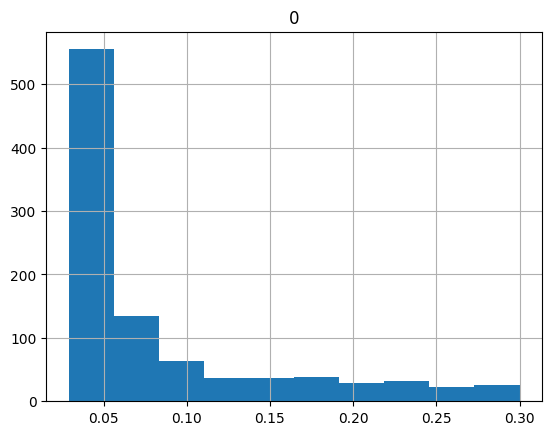

In [17]:
pd.DataFrame(metabolites_merged[metabolite_features].isna().sum() / metabolites_merged[metabolite_features].shape[0]).hist()

In [18]:
# Define formula for results and look at the difference between including GFR vs not 
formula_mets = ("{feature} ~ C(sex) + age + BMI_CALC + C(abx_recency_three) + " 
               "C(abx_recency_twelve) + C(meds_cholesterol) + C(meds_blood_sugar) + "
               "PC1 + PC2 + PC3 + PC4 + PC5 + centered_eGFR")
abx_term_three = "C(abx_recency_three)[T.1]"
abx_term_twelve = "C(abx_recency_twelve)[T.1]"
chol_term = "C(meds_cholesterol)[T.Yes]"
sugar_term = "C(meds_blood_sugar)[T.Yes]"

## Three month regression

In [19]:
tests_threemo = run_tests(args, df, formula_mets, abx_term_three)

Output()

In [20]:
sig_three = tests_threemo[tests_threemo["q"]<0.1].sort_values(by='q')

In [21]:
# Merge onto annotations
tests_three_anns = pd.merge(tests_threemo, anns_snapshot, on="feature")
tests_three_anns_sig = (tests_three_anns[tests_three_anns["q"]<0.1]
                        [['beta', 'se', 'n', 'q','CHEMICAL_NAME', 'SUB_PATHWAY']])

In [22]:
tests_three_anns_sig.sort_values(by='beta')

,beta,se,n,q,CHEMICAL_NAME,SUB_PATHWAY
172,-0.425302,0.086404,1150.0,0.000477,3-phenylpropionate (hydrocinnamate),Benzoate Metabolism
435,-0.423804,0.082279,1175.0,0.000296,cinnamoylglycine,Food Component/Plant
882,-0.398526,0.097856,1030.0,0.007728,X - 15728,NaN
251,-0.357861,0.096889,918.0,0.018991,5-hydroxyhexanoate,"Fatty Acid, Monohydroxy"
869,-0.326907,0.081231,1235.0,0.007728,X - 12216,NaN
255,-0.323242,0.076133,1265.0,0.004548,3-hydroxy-2-ethylpropionate,"Leucine, Isoleucine and Valine Metabolism"
215,-0.319702,0.083532,1247.0,0.012023,acetylcarnitine (C2),"Fatty Acid Metabolism (Acyl Carnitine, Short C..."
173,-0.310749,0.081187,1239.0,0.012023,hippurate,Benzoate Metabolism
854,-0.297896,0.092314,1046.0,0.061757,X - 12544,NaN
851,-0.296956,0.092282,979.0,0.061757,X - 21442,NaN


In [23]:
# # Checks which bile acids were tested
# tests_three_anns.dropna()[tests_three_anns['SUB_PATHWAY'].dropna().str.contains("Bile")]['CHEMICAL_NAME'].tolist()
# tests_three_anns.dropna()[tests_three_anns['SUB_PATHWAY'].dropna().str.contains("Bile")]

## Regressions to extract betas from 3-12 months

In [24]:
# Now find the betas for 12 months
tests_twelvemo = run_tests(args, df, formula_mets, abx_term_twelve)

Output()

In [25]:
tests_twelve_anns = pd.merge(tests_twelvemo, anns_snapshot, on="feature")
tests_twelve_anns_sig = (tests_twelve_anns[tests_twelve_anns["q"]<0.1]
                         [['beta','se','n', 'q', 'CHEMICAL_NAME', 'SUB_PATHWAY']])

In [26]:
sig_hists_twelve_list = tests_twelve_anns[tests_twelve_anns["q"]<0.1]['feature'].tolist()

### Save lists of significant hits

In [27]:
# Includes metabolite_ prefix
sig_hists_twelve_list = tests_twelve_anns[tests_twelve_anns["q"]<0.1]['feature'].tolist()
sig_hists_three_list = tests_three_anns[tests_three_anns["q"]<0.1]['feature'].tolist()
sig_hits_metab_number = list(set(sig_hists_three_list + sig_hists_twelve_list))

# Just metabolon id
sig_metabolon_ids = [s.split("_", 1)[1] for s in sig_hits_metab_number]

# By chemical name
all_sig_metabs_names = list(set(list(tests_twelve_anns_sig.CHEMICAL_NAME) +
                                list(tests_three_anns_sig.CHEMICAL_NAME)))

In [28]:
# all_sig_metabs_names
len(sig_hits_metab_number)

32

## Extract beta coefficients associated with cholesterol and blood sugar lowering medication use

In [29]:
tests_chol = run_tests(args, df, formula_mets, chol_term)
tests_chol_anns = pd.merge(tests_chol, anns_snapshot, on="feature")
tests_chol_anns_subset = tests_chol_anns[tests_chol_anns.CHEMICAL_NAME.isin(all_sig_metabs_names)]

Output()

In [30]:
tests_sugar = run_tests(args, df, formula_mets, sugar_term)
tests_sugar_anns = pd.merge(tests_sugar, anns_snapshot, on="feature")
tests_sugar_anns_subset = tests_sugar_anns[tests_sugar_anns.CHEMICAL_NAME.isin(all_sig_metabs_names)]

Output()

## Get beta and q-value dataframes for plotting in R

In [31]:
metabs_betas = (tests_three_anns[tests_three_anns.CHEMICAL_NAME.isin(all_sig_metabs_names)]
                [['CHEMICAL_NAME','beta']].rename(columns={'beta':'abx_three'}))

# Add twelve month betas
metabs_betas = metabs_betas.merge(tests_twelve_anns[['CHEMICAL_NAME','beta']].copy(),
                                  how='left', on='CHEMICAL_NAME').rename(
    columns={'beta':'abx_twelve'})

metabs_betas = metabs_betas.merge(tests_chol_anns_subset[['CHEMICAL_NAME','beta']].copy(),
                                  how='left', on='CHEMICAL_NAME').rename(
    columns={'beta':'chol_meds'})

metabs_betas = metabs_betas.merge(tests_sugar_anns_subset[['CHEMICAL_NAME','beta']].copy(),
                                  how='left', on='CHEMICAL_NAME').rename(
    columns={'beta':'blood_sugar_meds'})

metabs_betas

,CHEMICAL_NAME,abx_three,abx_twelve,chol_meds,blood_sugar_meds
0,glutarate (C5-DC),0.386387,0.098197,0.051383,0.285104
1,alpha-ketobutyrate,-0.290272,-0.022889,0.033312,0.609669
2,3-phenylpropionate (hydrocinnamate),-0.425302,-0.207168,-0.076640,-0.031335
3,hippurate,-0.310749,-0.213062,-0.165728,-0.151796
4,4-methyl-2-oxopentanoate,-0.235198,-0.099729,0.020687,0.532149
5,alpha-hydroxyisocaproate,-0.240082,-0.094191,-0.047424,0.281556
6,phenyllactate (PLA),-0.231256,-0.120232,-0.058598,0.115497
7,acetylcarnitine (C2),-0.319702,-0.066922,-0.123283,0.115206
8,indolepropionate,-0.257387,-0.316069,-0.046714,-0.327767
9,3-hydroxylaurate,-0.265493,-0.135663,-0.076200,0.318170


In [32]:
metabs_q_values = (tests_three_anns[tests_three_anns.CHEMICAL_NAME.isin(all_sig_metabs_names)]
                   [['CHEMICAL_NAME','q']].rename(columns={'q':'abx_three'}))

# Add twelve month betas
metabs_q_values = metabs_q_values.merge(tests_twelve_anns[['CHEMICAL_NAME','q']].copy(),
                                        how='left', on='CHEMICAL_NAME').rename(
    columns={'q':'abx_twelve'})

metabs_q_values = metabs_q_values.merge(tests_chol_anns_subset[['CHEMICAL_NAME','q']].copy(),
                                        how='left', on='CHEMICAL_NAME').rename(
    columns={'q':'chol_meds'})

metabs_q_values = metabs_q_values.merge(tests_sugar_anns_subset[['CHEMICAL_NAME','q']].copy(),
                                        how='left', on='CHEMICAL_NAME').rename(
    columns={'q':'blood_sugar_meds'})

metabs_q_values

,CHEMICAL_NAME,abx_three,abx_twelve,chol_meds,blood_sugar_meds
0,glutarate (C5-DC),0.002810,0.994409,0.771345,1.400002e-01
1,alpha-ketobutyrate,0.031559,0.994409,0.837493,2.121853e-04
2,3-phenylpropionate (hydrocinnamate),0.000477,0.336755,0.639383,9.375511e-01
3,hippurate,0.012023,0.219707,0.199846,5.187416e-01
4,4-methyl-2-oxopentanoate,0.072234,0.994409,0.885648,3.554878e-04
5,alpha-hydroxyisocaproate,0.054321,0.994409,0.747152,8.515729e-02
6,phenyllactate (PLA),0.065612,0.994409,0.684043,5.792827e-01
7,acetylcarnitine (C2),0.012023,0.994409,0.407408,6.415359e-01
8,indolepropionate,0.061757,0.001457,0.780395,6.894425e-02
9,3-hydroxylaurate,0.070538,0.994409,0.639383,9.250717e-02


In [33]:
metabs_betas.to_csv("data/rh_metabs_betas.csv", index=False)
metabs_q_values.to_csv("data/rh_metabs_qs.csv", index=False)